# Lab 7: Python Physics Engine Prototype

Name: Aidan Siddiqi 
Date: 10/18/2026
Lab: PHYS 311 Module 7

This notebook demonstrates the lab07_engine package. The engine has four parts: Body, Force, Integrator, and World. It reproduces four earlier labs using only engine calls, then runs an original multi-body scene.

**AI use disclaimer:** AI (Claude) was used in preparing this notebook for coding assistance, tidying up code, and improving code flow/organization. This is not to say that there was no human work done in this code; all lines included input and assistance from myself and many iterations and human attempts are consolidated into the notebook seen below. For this one especially, Claude was used to make all code look neat and assist with flow and connected files. This one was quite difficult.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from lab07_engine import Body, World, Force
from lab07_engine import Gravity, Drag, Spring, NewtonGravity
from lab07_engine import Euler, EulerCromer, VelocityVerlet
from lab07_engine import CircleCollisions, BoxWalls

## Part A: The Engine

The engine is a small package called lab07_engine. It has one file for each component, so each piece is short and can be read and ported on its own.

```
lab07_engine/
    __init__.py        exports the public names
    body.py            Body
    forces.py          Force, Gravity, Drag, Spring, NewtonGravity
    integrators.py     Euler, EulerCromer, VelocityVerlet
    collisions.py      CircleCollisions, BoxWalls
    world.py           World
```

### Class diagram

```
World  (owns everything and runs the loop)
  |
  |-- bodies: list of Body
  |       Body holds m, r, v, radius, theta, omega, I, fixed, force, torque
  |
  |-- forces: list of Force
  |       Force has apply(world) and potential_energy(world)
  |       Gravity, Drag, Spring, NewtonGravity
  |
  |-- integrator: one Integrator
  |       Integrator has step(world, dt)
  |       Euler, EulerCromer, VelocityVerlet
  |
  |-- colliders: list of Collider
          Collider has resolve(world)
          CircleCollisions, BoxWalls
```

Who talks to whom:

```
Force.apply(world)          adds to      Body.force and Body.torque
                                              |
                                              | read by
                                              v
Integrator.step(world, dt)  updates      Body.r, v, theta, omega
                                              |
                                              v
Collider.resolve(world)     changes      Body.v and Body.r at contacts
```

One call to World.step(dt) does five things:

1. Clear every body's force and torque accumulator.
2. Let every force in the list add to the accumulators.
3. Let the integrator read the accumulators and advance the state.
4. Let every collider detect and resolve contacts.
5. Advance the clock.

Design choices:

- A force never needs to know what other forces exist. It only adds to body.force.
- A fixed body has an inverse mass of zero, so no force can move it. There is no if-statement for it in the forces.
- Each force reports its own potential energy. Dissipative forces report zero, so total energy should fall when drag is present.
- Spring and NewtonGravity compute one vector per pair and apply +f to one body and -f to the other. Momentum is conserved because there is only one number.
- A watcher is a name plus a function of the world. The engine never hard-codes which quantities matter.

The engine in six lines. This is Lab 1's projectile.

In [2]:
world = World(EulerCromer())
ball = world.add_body(Body(mass=1.0, pos=(0, 0), vel=(15, 20), name='ball'))
world.add_force(Gravity(9.81))
world.watch_positions()
world.watch_conserved()
data = world.run(dt=0.01, t_end=4.0)

print("Recorded quantities:", list(data.keys()))
print("Number of recorded points:", len(data['t']))
print(f"Position at t = 4 s: ({data['ball.x'][-1]:.3f}, {data['ball.y'][-1]:.3f})")

Recorded quantities: ['t', 'ball.x', 'ball.y', 'ball.vx', 'ball.vy', 'E', 'px', 'py', 'L']
Number of recorded points: 401
Position at t = 4 s: (60.000, 1.324)


The force accumulator in action. The world clears every accumulator before the forces fill it again, so nothing doubles up.

In [3]:
demo = World(EulerCromer())
ball = demo.add_body(Body(mass=1.0, pos=(0, 0), vel=(15, 20), name='ball'))
demo.add_force(Gravity(9.81))

demo.compute_forces()
print("Gravity only:      ", ball.force)

demo.add_force(Drag(c=0.5))
demo.compute_forces()
print("Gravity plus drag: ", ball.force)

demo.compute_forces()
print("Computed again:    ", ball.force)

Gravity only:       [ 0.   -9.81]
Gravity plus drag:  [-187.5  -259.81]
Computed again:     [-187.5  -259.81]


## Part B: Validate Against Old Labs

Each section below rebuilds an earlier lab using only engine calls. There are no hand-written simulation loops on the engine side.

The original lab code is pasted in as the baseline. The functions are unchanged except for the names, which are changed so they do not clash.

### B.1 Projectile (Labs 1-2)

In [4]:
def simulate_lab2(method, dt, v0=30.0, angle_deg=50.0, g=9.81, m=1.0):
    theta = np.radians(angle_deg)
    x, y = 0.0, 0.0
    vx, vy = v0 * np.cos(theta), v0 * np.sin(theta)
    t = 0.0

    KE0 = 0.5 * m * (vx**2 + vy**2)
    PE0 = m * g * y

    t_list, x_list, y_list = [t], [x], [y]
    vx_list, vy_list = [vx], [vy]
    KE_list, PE_list, E_list = [KE0], [PE0], [KE0 + PE0]

    while y >= 0:
        ax, ay = 0.0, -g

        if method == 'euler':
            x = x + vx * dt
            y = y + vy * dt
            vx = vx + ax * dt
            vy = vy + ay * dt
        elif method == 'euler-cromer':
            vx = vx + ax * dt
            vy = vy + ay * dt
            x = x + vx * dt
            y = y + vy * dt

        t = t + dt
        KE = 0.5 * m * (vx**2 + vy**2)
        PE = m * g * y
        E = KE + PE

        t_list.append(t)
        x_list.append(x)
        y_list.append(y)
        vx_list.append(vx)
        vy_list.append(vy)
        KE_list.append(KE)
        PE_list.append(PE)
        E_list.append(E)

    return (np.array(t_list), np.array(x_list), np.array(y_list),
            np.array(vx_list), np.array(vy_list),
            np.array(KE_list), np.array(PE_list), np.array(E_list))

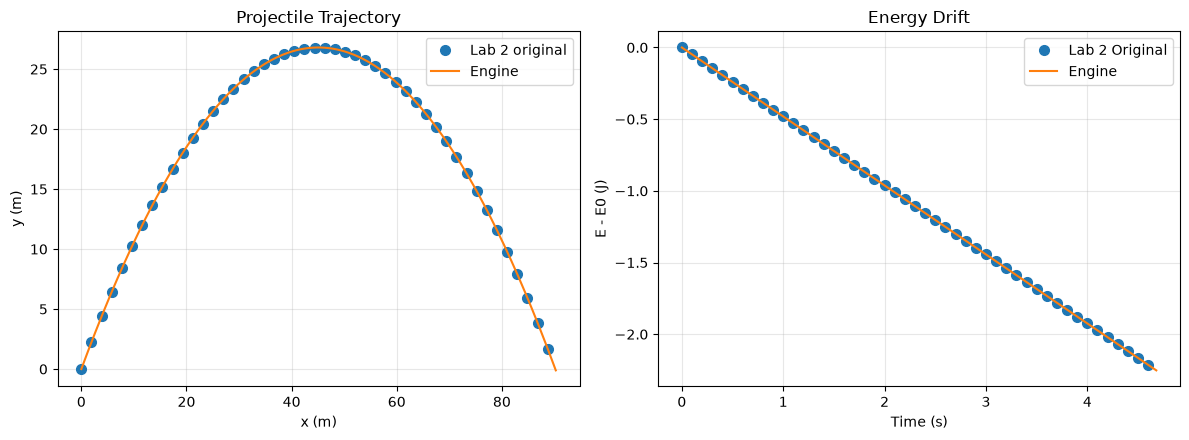

Steps: original = 468, engine = 468
Max |x difference| = 0.00e+00 m
Max |y difference| = 0.00e+00 m
Max |E difference| = 0.00e+00 J
Range: original = 90.2474 m, engine = 90.2474 m
Engine energy drift: -2.2519 J, -0.500 % of E0


In [5]:
dt = 0.01
v0, angle = 30.0, 50.0

t_o, x_o, y_o, vx_o, vy_o, KE_o, PE_o, E_o = simulate_lab2('euler-cromer', dt)

world = World(EulerCromer())
world.add_body(Body(mass=1.0, pos=(0, 0),
                    vel=(v0 * np.cos(np.radians(angle)), v0 * np.sin(np.radians(angle))),
                    name='ball'))
world.add_force(Gravity(9.81))
world.watch_positions()
world.watch_conserved()
data = world.run(dt, t_end=10.0, stop=lambda w: w.bodies[0].r[1] < 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(x_o[::10], y_o[::10], 'o', markersize=7, label='Lab 2 original')
ax[0].plot(data['ball.x'], data['ball.y'], '-', label='Engine')
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_title('Projectile Trajectory')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(t_o[::10], E_o[::10] - E_o[0], 'o', markersize=7, label='Lab 2 Original')
ax[1].plot(data['t'], data['E'] - data['E'][0], '-', label='Engine')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('E - E0 (J)')
ax[1].set_title('Energy Drift')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Steps: original = {len(t_o) - 1}, engine = {len(data['t']) - 1}")
print(f"Max |x difference| = {np.max(np.abs(data['ball.x'] - x_o)):.2e} m")
print(f"Max |y difference| = {np.max(np.abs(data['ball.y'] - y_o)):.2e} m")
print(f"Max |E difference| = {np.max(np.abs(data['E'] - E_o)):.2e} J")
print(f"Range: original = {x_o[-1]:.4f} m, engine = {data['ball.x'][-1]:.4f} m")
print(f"Engine energy drift: {data['E'][-1] - data['E'][0]:.4f} J, {(data['E'][-1] - data['E'][0]) / data['E'][0] * 100:.3f} % of E0")

The engine reproduces the Lab 2 Euler-Cromer run. The trajectories agree to rounding error and both runs take the same number of steps. The energy drift is the same one seen in Lab 2. It is small, negative, and grows steadily through the flight. This is the conservation check for this section.

### B.2 Oscillator (Lab 3)

In [6]:
def simulate_sho(method, dt, n_periods=10, k=1.0, m=1.0, x0=1.0, v0=0.0):
    omega0 = np.sqrt(k / m)
    T = 2 * np.pi / omega0
    t_max = n_periods * T

    x, v = x0, v0
    t = 0.0
    ts, xs, vs = [t], [x], [v]
    Es = [0.5 * k * x**2 + 0.5 * m * v**2]

    while t < t_max:
        a = -(k / m) * x

        if method == 'euler':
            x_new = x + v * dt
            v_new = v + a * dt
            x, v = x_new, v_new
        elif method == 'euler-cromer':
            v = v + a * dt
            x = x + v * dt

        t = t + dt
        E = 0.5 * k * x**2 + 0.5 * m * v**2

        ts.append(t)
        xs.append(x)
        vs.append(v)
        Es.append(E)

    return np.array(ts), np.array(xs), np.array(vs), np.array(Es)

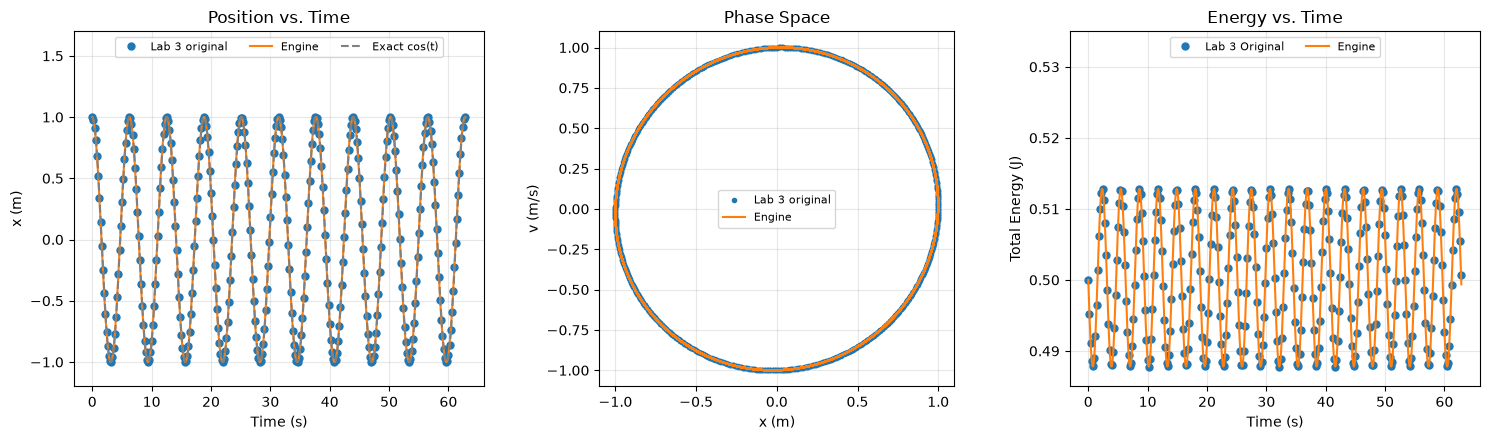

Steps: original = 1257, engine = 1257
Max |x difference| = 1.89e-15
Max |v difference| = 1.61e-15
Max |E difference| = 9.99e-16
Period: engine = 6.2825 s, exact 2*pi = 6.2832 s
Engine max |dE|/E0 = 0.0256


In [7]:
dt = 0.05
T_exact = 2 * np.pi

t_o, x_o, v_o, E_o = simulate_sho('euler-cromer', dt)

world = World(EulerCromer())
anchor = world.add_body(Body(mass=1.0, pos=(0, 0), fixed=True, name='anchor'))
bob = world.add_body(Body(mass=1.0, pos=(1, 0), name='bob'))
world.add_force(Spring(anchor, bob, k=1.0, rest=0.0))
world.watch_positions()
world.watch_conserved()
data = world.run(dt, t_end=10 * T_exact)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

ax[0].plot(t_o[::4], x_o[::4], 'o', markersize=5, label='Lab 3 original')
ax[0].plot(data['t'], data['bob.x'], '-', label='Engine')
ax[0].plot(data['t'], np.cos(data['t']), '--', color='gray', label='Exact cos(t)')
ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('x (m)')
ax[0].set_title('Position vs. Time')
ax[0].set_ylim(-1.2, 1.7)
ax[0].legend(fontsize=8, loc='upper center', ncol=3)
ax[0].grid(alpha=0.3)

ax[1].plot(x_o, v_o, 'o', markersize=3, label='Lab 3 original')
ax[1].plot(data['bob.x'], data['bob.vx'], '-', label='Engine')
ax[1].set_xlabel('x (m)')
ax[1].set_ylabel('v (m/s)')
ax[1].set_title('Phase Space')
ax[1].legend(fontsize=8)
ax[1].set_aspect('equal')
ax[1].grid(alpha=0.3)

ax[2].plot(t_o[::4], E_o[::4], 'o', markersize=5, label='Lab 3 Original')
ax[2].plot(data['t'], data['E'], '-', label='Engine')
ax[2].set_xlabel('Time (s)')
ax[2].set_ylabel('Total Energy (J)')
ax[2].set_title('Energy vs. Time')
ax[2].set_ylim(0.485, 0.535)
ax[2].legend(fontsize=8, loc='upper center', ncol=2)
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

x_e, t_e = data['bob.x'], data['t']
up = np.where((x_e[:-1] < 0) & (x_e[1:] >= 0))[0]
crossings = t_e[up] - x_e[up] * (t_e[up + 1] - t_e[up]) / (x_e[up + 1] - x_e[up])
T_engine = np.mean(np.diff(crossings))

print(f"Steps: original = {len(t_o) - 1}, engine = {len(data['t']) - 1}")
print(f"Max |x difference| = {np.max(np.abs(data['bob.x'] - x_o)):.2e}")
print(f"Max |v difference| = {np.max(np.abs(data['bob.vx'] - v_o)):.2e}")
print(f"Max |E difference| = {np.max(np.abs(data['E'] - E_o)):.2e}")
print(f"Period: engine = {T_engine:.4f} s, exact 2*pi = {T_exact:.4f} s")
print(f"Engine max |dE|/E0 = {np.max(np.abs(data['E'] - data['E'][0])) / data['E'][0]:.4f}")

The engine matches the Lab 3 Euler-Cromer run to rounding error. The phase-space curve is a closed ellipse and the energy stays in a bounded band instead of growing. The period is close to the exact value of 2*pi. The spring is attached to a fixed anchor body, so the same Spring class that links two moving bodies also works for Lab 3.

### B.3 Orbit with Velocity Verlet (Lab 5)

In [8]:
G, M = 1.0, 1.0

def accel(r):
    dist = np.linalg.norm(r)
    return -G * M * r / dist**3

def verlet_step(r, v, a, dt, accel_func):
    r_new = r + v * dt + 0.5 * a * dt**2
    a_new = accel_func(r_new)
    v_new = v + 0.5 * (a + a_new) * dt
    return r_new, v_new, a_new

def energy(r, v, G=1.0, M=1.0, m=1.0):
    ke = 0.5 * m * np.dot(v, v)
    pe = -G * M * m / np.linalg.norm(r)
    return ke + pe

def simulate_lab5(method, dt, n_steps, r0=np.array([1.0, 0.0]), v0=np.array([0.0, 0.8])):
    r, v = r0.copy(), v0.copy()
    a = accel(r)

    rs = [r.copy()]
    Es = [energy(r, v)]

    for _ in range(n_steps):
        if method == 'euler':
            r_new = r + v * dt
            v_new = v + a * dt
            r, v = r_new, v_new
            a = accel(r)
        elif method == 'euler-cromer':
            v = v + a * dt
            r = r + v * dt
            a = accel(r)
        elif method == 'verlet':
            r, v, a = verlet_step(r, v, a, dt, accel)

        rs.append(r.copy())
        Es.append(energy(r, v))

    return np.array(rs), np.array(Es)

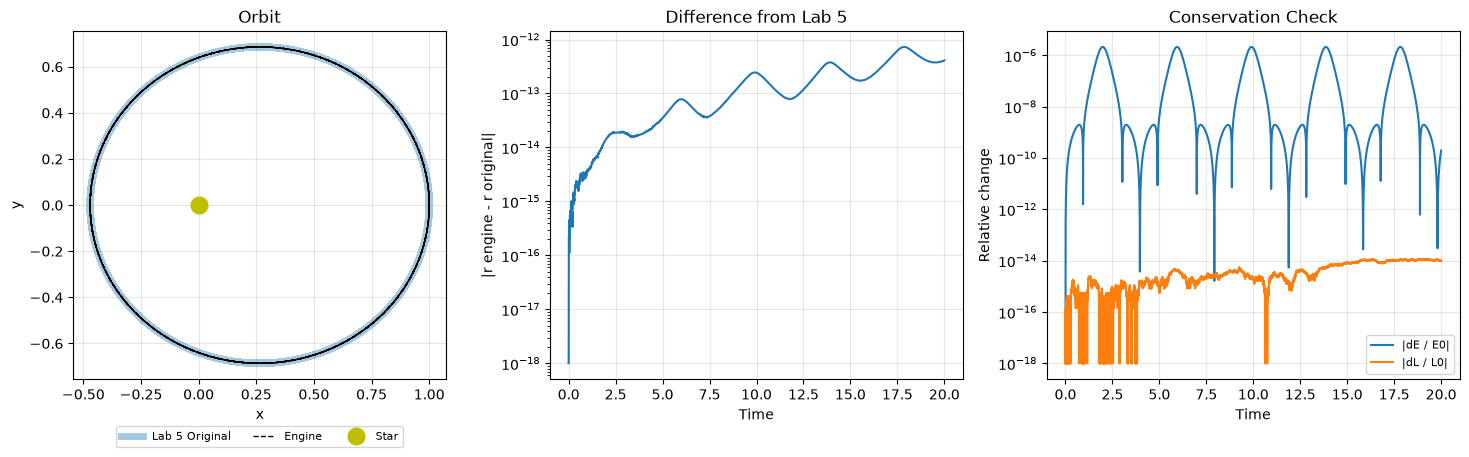

Max position difference from Lab 5 = 7.29e-13
Max |E difference| from Lab 5 = 3.42e-14
Engine max |dE/E0| = 2.132e-06
Engine max |dL/L0| = 1.166e-14


In [9]:
dt = 0.001
n_steps = 20000

rs_o, Es_o = simulate_lab5('verlet', dt, n_steps)

world = World(VelocityVerlet())
world.add_body(Body(mass=1.0, pos=(0, 0), fixed=True, name='star'))
world.add_body(Body(mass=1.0, pos=(1, 0), vel=(0, 0.8), name='planet'))
world.add_force(NewtonGravity(G=1.0))
world.watch_positions()
world.watch_conserved()
data = world.run(dt, steps=n_steps)

dr = np.hypot(data['planet.x'] - rs_o[:, 0], data['planet.y'] - rs_o[:, 1])
dE_rel = np.abs(data['E'] - data['E'][0]) / abs(data['E'][0])
dL_rel = np.abs(data['L'] - data['L'][0]) / abs(data['L'][0])

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

ax[0].plot(rs_o[:, 0], rs_o[:, 1], '-', linewidth=5, alpha=0.4, label='Lab 5 Original')
ax[0].plot(data['planet.x'], data['planet.y'], 'k--', linewidth=1, label='Engine')
ax[0].plot(0, 0, 'yo', markersize=12, label='Star')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('Orbit')
ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
ax[0].set_aspect('equal')
ax[0].grid(alpha=0.3)

ax[1].semilogy(data['t'], dr + 1e-18)
ax[1].set_xlabel('Time')
ax[1].set_ylabel('|r engine - r original|')
ax[1].set_title('Difference from Lab 5')
ax[1].grid(alpha=0.3)

ax[2].semilogy(data['t'], dE_rel + 1e-18, label='|dE / E0|')
ax[2].semilogy(data['t'], dL_rel + 1e-18, label='|dL / L0|')
ax[2].set_xlabel('Time')
ax[2].set_ylabel('Relative change')
ax[2].set_title('Conservation Check')
ax[2].legend(fontsize=8)
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Max position difference from Lab 5 = {np.max(dr):.2e}")
print(f"Max |E difference| from Lab 5 = {np.max(np.abs(data['E'] - Es_o)):.2e}")
print(f"Engine max |dE/E0| = {np.max(dE_rel):.3e}")
print(f"Engine max |dL/L0| = {np.max(dL_rel):.3e}")

The engine reproduces the Lab 5 Verlet orbit. The two paths differ by a few times 1e-13 after 20000 steps, which is likely just noise. The energy error matches the Lab 5 value of a few parts per million. Angular momentum is conserved to machine precision. A central force gives no torque, and Verlet notes that. The star is a fixed Body, and its pair potential energy is still counted by NewtonGravity.

### B.4 Collisions (Lab 4)

In [10]:
def collide_1d(m1, m2, u1, u2, e=1.0):
    total_m = m1 + m2
    v_cm = (m1 * u1 + m2 * u2) / total_m
    v1 = v_cm - e * (m2 / total_m) * (u1 - u2)
    v2 = v_cm + e * (m1 / total_m) * (u1 - u2)
    return v1, v2

def collide_2d(m1, m2, r1, r2, v1, v2, e=1.0):
    r1, r2 = np.asarray(r1, float), np.asarray(r2, float)
    v1, v2 = np.asarray(v1, float), np.asarray(v2, float)

    n = r2 - r1
    dist = np.linalg.norm(n)
    if dist == 0:
        return v1, v2
    n = n / dist

    u1n, u2n = np.dot(v1, n), np.dot(v2, n)
    v1t = v1 - u1n * n
    v2t = v2 - u2n * n

    new1n, new2n = collide_1d(m1, m2, u1n, u2n, e)

    return v1t + new1n * n, v2t + new2n * n

def overlapping(r1, r2, radius1, radius2):
    return np.linalg.norm(np.asarray(r2) - np.asarray(r1)) < (radius1 + radius2)

def simulate_box_lab4(e, n_steps=450, W=10.0, H=6.0, dt=0.01):
    bodies = [
        {'m': 2.0, 'r': np.array([1.0, 3.0]), 'v': np.array([2.0, 0.0]), 'radius': 0.3},
        {'m': 5.0, 'r': np.array([9.0, 3.4]), 'v': np.array([-1.0, 0.0]), 'radius': 0.5},
    ]
    ke_hist = []
    first_collision = None

    for step in range(n_steps):
        for b in bodies:
            b['r'] = b['r'] + b['v'] * dt

        for b in bodies:
            if b['r'][0] - b['radius'] < 0 or b['r'][0] + b['radius'] > W:
                b['v'][0] = -b['v'][0]
                b['r'][0] = np.clip(b['r'][0], b['radius'], W - b['radius'])
            if b['r'][1] - b['radius'] < 0 or b['r'][1] + b['radius'] > H:
                b['v'][1] = -b['v'][1]
                b['r'][1] = np.clip(b['r'][1], b['radius'], H - b['radius'])

        b1, b2 = bodies
        approaching = np.dot(b2['v'] - b1['v'], b2['r'] - b1['r']) < 0
        ke_before_step = sum(0.5 * b['m'] * np.dot(b['v'], b['v']) for b in bodies)

        if overlapping(b1['r'], b2['r'], b1['radius'], b2['radius']) and approaching:
            if first_collision is None:
                n = (b2['r'] - b1['r']) / np.linalg.norm(b2['r'] - b1['r'])
                u1n, u2n = np.dot(b1['v'], n), np.dot(b2['v'], n)
            b1['v'], b2['v'] = collide_2d(b1['m'], b2['m'], b1['r'], b2['r'], b1['v'], b2['v'], e)
            ke_after_step = sum(0.5 * b['m'] * np.dot(b['v'], b['v']) for b in bodies)
            if first_collision is None:
                first_collision = (ke_before_step, ke_after_step, u1n, u2n)

        ke_hist.append(sum(0.5 * b['m'] * np.dot(b['v'], b['v']) for b in bodies))

    return np.array(ke_hist), first_collision

In [11]:
def engine_first_collision(e):
    world = World(EulerCromer())
    world.add_body(Body(mass=2.0, pos=(1.0, 3.0), vel=(2.0, 0.0), radius=0.3, name='a'))
    world.add_body(Body(mass=5.0, pos=(9.0, 3.4), vel=(-1.0, 0.0), radius=0.5, name='b'))
    world.add_collider(BoxWalls(0, 10, 0, 6, e=1.0))
    pairs = world.add_collider(CircleCollisions(e=e))
    world.watch('KE', lambda w: w.kinetic_energy())
    world.watch_positions()
    data = world.run(0.01, t_end=4.5, stop=lambda w: pairs.count >= 1)

    n = np.array([data['b.x'][-1] - data['a.x'][-1], data['b.y'][-1] - data['a.y'][-1]])
    n = n / np.linalg.norm(n)
    v_rel = np.array([data['a.vx'][-2] - data['b.vx'][-2], data['a.vy'][-2] - data['b.vy'][-2]])
    return data, np.dot(v_rel, n)

m_a, m_b = 2.0, 5.0
mu = m_a * m_b / (m_a + m_b)

print(f"{'e':<6}{'Lab 4 loss (%)':<18}{'Engine loss (%)':<18}{'Theory loss (%)':<18}")
for e in [1.0, 0.9, 0.7, 0.5]:
    _, first = simulate_box_lab4(e)
    loss_o = (first[0] - first[1]) / first[0] * 100

    d, approach = engine_first_collision(e)
    ke_before, ke_after = d['KE'][-2], d['KE'][-1]
    loss_e = (ke_before - ke_after) / ke_before * 100

    loss_t = 0.5 * mu * approach**2 * (1 - e**2) / ke_before * 100

    loss_o, loss_e = round(loss_o, 9) + 0.0, round(loss_e, 9) + 0.0
    print(f"{e:<6}{loss_o:<18.3f}{loss_e:<18.3f}{loss_t:<18.3f}")

e     Lab 4 loss (%)    Engine loss (%)   Theory loss (%)   
1.0   0.000             0.000             0.000             
0.9   13.961            13.961            13.961            
0.7   37.473            37.473            37.473            
0.5   55.107            55.107            55.107            


In [12]:
print(f"{'e':<6}{'pair collisions':<18}{'max |dp|':<14}{'KE retained (%)':<18}")
for e in [1.0, 0.5, 0.0]:
    world = World(EulerCromer())
    world.add_body(Body(mass=2.0, pos=(1.0, 3.0), vel=(2.0, 0.0), radius=0.3))
    world.add_body(Body(mass=5.0, pos=(9.0, 3.4), vel=(-1.0, 0.0), radius=0.5))
    pairs = world.add_collider(CircleCollisions(e=e))
    world.watch_conserved()
    world.watch('KE', lambda w: w.kinetic_energy())
    d = world.run(0.01, t_end=6.0)
    dp = np.hypot(d['px'] - d['px'][0], d['py'] - d['py'][0])
    print(f"{e:<6}{pairs.count:<18}{np.max(dp):<14.2e}{d['KE'][-1] / d['KE'][0] * 100:<18.2f}")

e     pair collisions   max |dp|      KE retained (%)   
1.0   1                 4.44e-16      100.00            
0.5   1                 5.55e-16      44.89             
0.0   1                 4.44e-16      26.52             


The first table checks the energy lost in the first ball-ball collision. The engine, the original Lab 4 code, and the head-on theory formula all agree. The collision resolution in the engine uses the same collide_2d function as Lab 4.

The second table is the conservation check, with the walls turned off so the system is isolated. Momentum is conserved to rounding error at every restitution value, even at e = 0 where almost three quarters of the kinetic energy is gone.

## Part C: An Original Multi-Body Scene

The scene is twelve balls in a box. The balls have different radii and masses. They fall under gravity, feel quadratic air drag, and bounce off the walls and each other with a restitution of 0.9.

Two forces act on every ball, both gravity and drag. Two colliders handle contacts, BoxWalls and CircleCollisions. The integrator is Velocity Verlet. None of this needed a change to the engine.

In [13]:
def make_balls(world, n=12, seed=4, box=(10.0, 8.0), speed=3.0, inward=False):
    rng = np.random.default_rng(seed)
    placed = []
    while len(placed) < n:
        radius = rng.uniform(0.3, 0.5)
        pos = rng.uniform([radius, radius], [box[0] - radius, box[1] - radius])
        if all(np.linalg.norm(pos - p) > radius + rr + 0.05 for p, rr in placed):
            placed.append((pos, radius))

    for i, (pos, radius) in enumerate(placed):
        angle = rng.uniform(0, 2 * np.pi)
        vel = rng.uniform(0, speed) * np.array([np.cos(angle), np.sin(angle)])
        if inward:
            to_center = np.array([box[0] / 2, box[1] / 2]) - pos
            vel = rng.uniform(1.0, speed) * to_center / np.linalg.norm(to_center)
        world.add_body(Body(mass=2 * radius**2, pos=pos, vel=vel, radius=radius, name='ball' + str(i)))

def build_scene(gravity=True, drag=True, e=0.9, walls=True, pairs=True, inward=False, integrator=None):
    world = World(integrator if integrator is not None else VelocityVerlet())
    make_balls(world, inward=inward)
    if gravity:
        world.add_force(Gravity(9.81))
    if drag:
        world.add_force(Drag(0.02))
    if walls:
        world.add_collider(BoxWalls(0, 10, 0, 8, e=e))
    if pairs:
        world.add_collider(CircleCollisions(e=e))
    world.watch_conserved()
    world.watch('KE', lambda w: w.kinetic_energy())
    world.watch_positions()
    return world

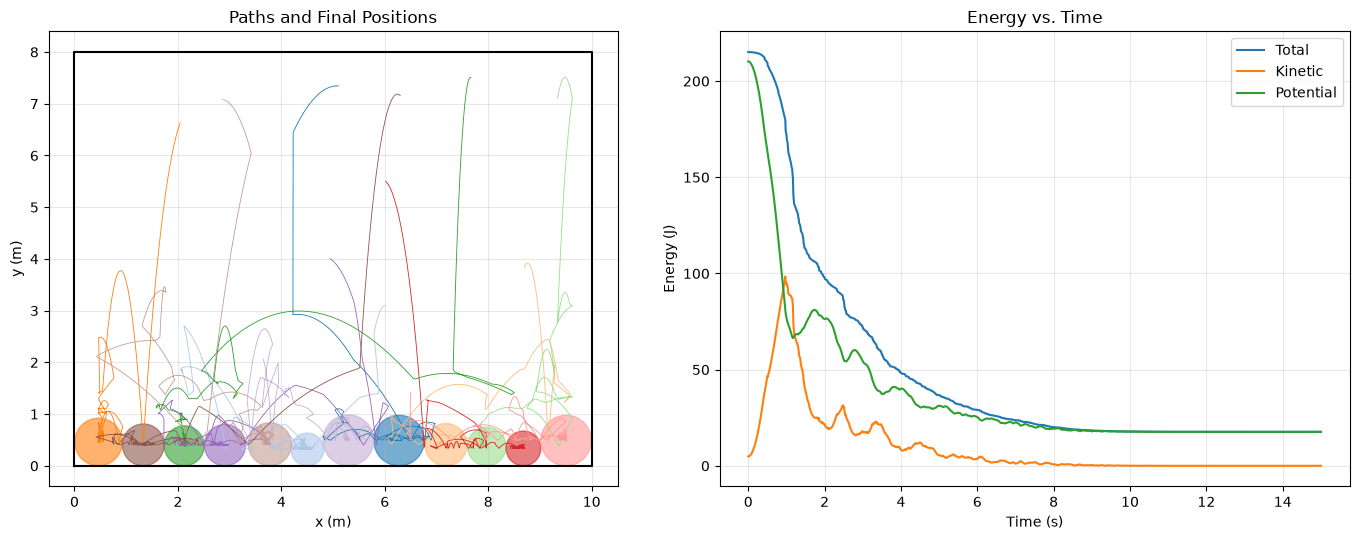

Ball-ball collisions: 634, wall hits: 3995
Total energy: start = 215.14 J, end = 17.66 J (91.8 % dissipated)
Largest rise in total energy between recorded points: 4.92e-04 J
Max change in momentum: 21.82 kg m/s


In [14]:
world = build_scene()
pair_hits = world.colliders[1]
wall_hits = world.colliders[0]
data = world.run(0.002, t_end=15.0, record_every=5)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

for i, b in enumerate(world.bodies):
    color = plt.cm.tab20(i)
    ax[0].plot(data[b.name + '.x'], data[b.name + '.y'], '-', linewidth=0.6, color=color)
    ax[0].add_patch(plt.Circle((b.r[0], b.r[1]), b.radius, color=color, alpha=0.6))
ax[0].plot([0, 10, 10, 0, 0], [0, 0, 8, 8, 0], 'k-')
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].set_title('Paths and Final Positions')
ax[0].set_aspect('equal')
ax[0].grid(alpha=0.3)

ax[1].plot(data['t'], data['E'], label='Total')
ax[1].plot(data['t'], data['KE'], label='Kinetic')
ax[1].plot(data['t'], data['E'] - data['KE'], label='Potential')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Energy (J)')
ax[1].set_title('Energy vs. Time')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

E = data['E']
dp = np.hypot(data['px'] - data['px'][0], data['py'] - data['py'][0])
print(f"Ball-ball collisions: {pair_hits.count}, wall hits: {wall_hits.count}")
print(f"Total energy: start = {E[0]:.2f} J, end = {E[-1]:.2f} J ({(E[0] - E[-1]) / E[0] * 100:.1f} % dissipated)")
print(f"Largest rise in total energy between recorded points: {max(np.diff(E).max(), 0):.2e} J")
print(f"Max change in momentum: {np.max(dp):.2f} kg m/s")

Total energy falls from the start to a small final value as the balls settle on the floor. The loss comes from drag and from the e = 0.9 bounces. The largest rise between recorded points is tiny compared with the total. Momentum changes a lot, which is correct. Gravity and the walls are external to the system.

Now the cases where a conservation law should hold. The next test removes drag and sets e = 1 so that energy should be conserved. The drift is checked at three step sizes.

dt = 0.004: max |dE|/E0 = 2.634 %
dt = 0.002: max |dE|/E0 = 1.341 %
dt = 0.001: max |dE|/E0 = 0.680 %


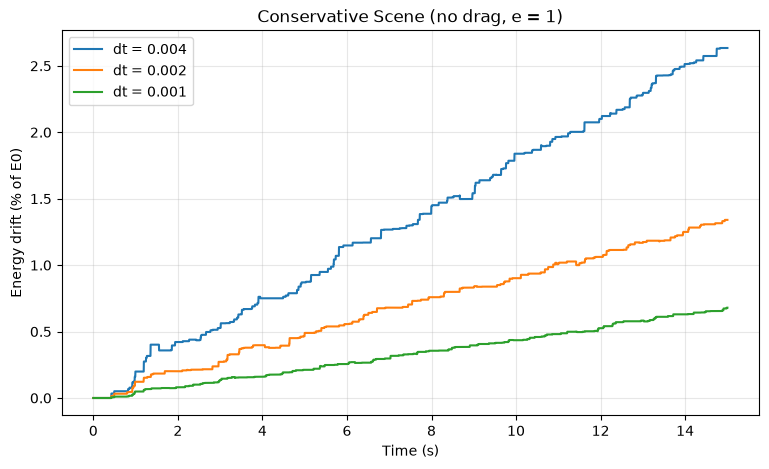

Walls only, no ball-ball collisions, dt = 0.002: max |dE|/E0 = 1.455 %


In [15]:
dts = [0.004, 0.002, 0.001]
every = [1, 2, 4]

plt.figure(figsize=(9, 5))
for dt, rec in zip(dts, every):
    world = build_scene(drag=False, e=1.0)
    d = world.run(dt, t_end=15.0, record_every=rec)
    drift = (d['E'] - d['E'][0]) / d['E'][0] * 100
    plt.plot(d['t'], drift, label=f"dt = {dt}")
    print(f"dt = {dt}: max |dE|/E0 = {np.max(np.abs(drift)):.3f} %")
plt.xlabel('Time (s)')
plt.ylabel('Energy drift (% of E0)')
plt.title('Conservative Scene (no drag, e = 1)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

world = build_scene(drag=False, e=1.0, pairs=False)
d = world.run(0.002, t_end=15.0, record_every=5)
print(f"Walls only, no ball-ball collisions, dt = 0.002: max |dE|/E0 = {np.max(np.abs(d['E'] - d['E'][0])) / d['E'][0] * 100:.3f} %")

The drift is not zero. It rises in small steps, one for each wall hit, and it shrinks roughly in proportion to dt. That makes it a step-size effect and not a physics error. Removing the ball-ball collisions leaves the drift almost unchanged, so it comes from the wall handling. When a ball is pushed back inside a wall after penetrating it, the correction lifts the ball slightly, which adds a little potential energy under gravity.

There is no gravity, no drag, and no walls. The balls start moving toward the center so that they collide often.

e = 1.0: 20 collisions, max |dp| = 1.81e-15, KE retained = 100.00 %
e = 0.5: 25 collisions, max |dp| = 1.11e-15, KE retained = 12.18 %


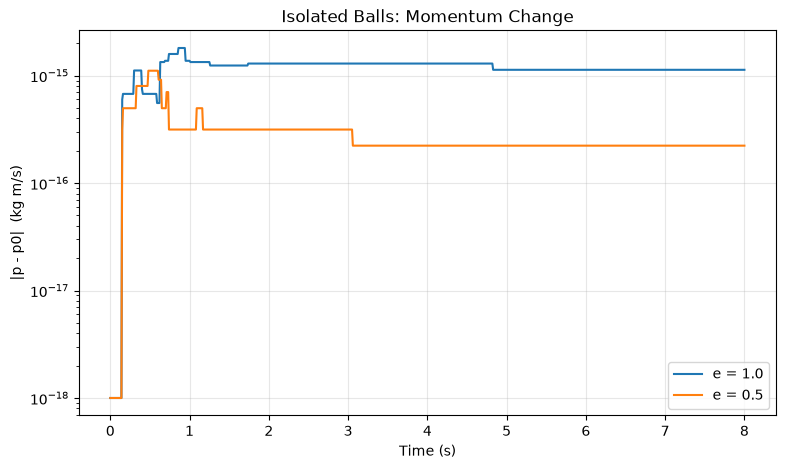

In [16]:
plt.figure(figsize=(9, 5))
for e in [1.0, 0.5]:
    world = build_scene(gravity=False, drag=False, walls=False, e=e, inward=True)
    pairs = world.colliders[0]
    d = world.run(0.002, t_end=8.0, record_every=5)
    dp = np.hypot(d['px'] - d['px'][0], d['py'] - d['py'][0])
    plt.semilogy(d['t'], dp + 1e-18, label=f"e = {e}")
    print(f"e = {e}: {pairs.count} collisions, max |dp| = {np.max(dp):.2e}, KE retained = {d['KE'][-1] / d['KE'][0] * 100:.2f} %")
plt.xlabel('Time (s)')
plt.ylabel('|p - p0|  (kg m/s)')
plt.title('Isolated Balls: Momentum Change')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Momentum is conserved to rounding error, even at e = 0.5 where most of the kinetic energy is lost. Energy is conserved at e = 1 and lost at e < 1. This is the Week 4 lesson, now running on the engine.

**Summary of the Part C checks**

| Run | Energy | Momentum |
|---|---|---|
| Full scene (gravity, drag, e = 0.9) | Falls, as expected | Not conserved, gravity and walls are external |
| Conservative (no drag, e = 1) | Conserved up to a small step-size drift | Not conserved, gravity and walls are external |
| Isolated (no gravity, no walls) | Conserved at e = 1, lost at e < 1 | Conserved to rounding error |

## Adding a New Force

A new force does not need any change to Body, Integrator, or World. This one is a constant wind.

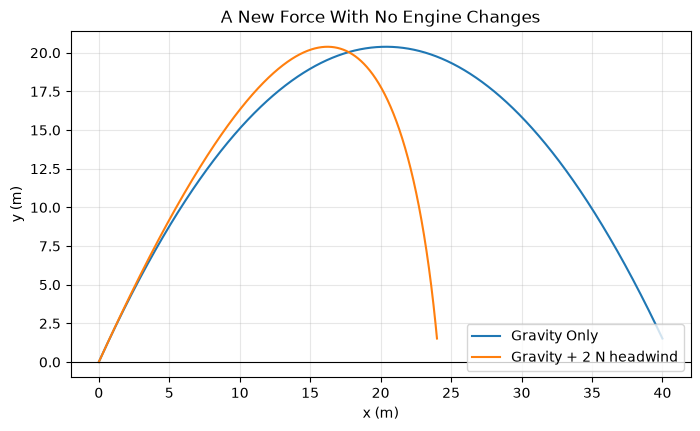

x at t = 4 s: no wind = 40.00 m, headwind = 24.00 m


In [17]:
class Wind(Force):
    def __init__(self, F):
        self.F = np.array(F, dtype=float)

    def apply(self, world):
        for b in world.bodies:
            if not b.fixed:
                b.force += self.F

def launch(forces):
    world = World(VelocityVerlet())
    world.add_body(Body(mass=1.0, pos=(0, 0), vel=(10, 20), name='ball'))
    for f in forces:
        world.add_force(f)
    world.watch_positions()
    return world.run(0.001, t_end=4.0)

calm = launch([Gravity(9.81)])
windy = launch([Gravity(9.81), Wind((-2.0, 0.0))])

plt.figure(figsize=(8, 4.5))
plt.plot(calm['ball.x'], calm['ball.y'], label='Gravity Only')
plt.plot(windy['ball.x'], windy['ball.y'], label='Gravity + 2 N headwind')
plt.axhline(0, color='k', linewidth=0.8)
plt.ylim(bottom=-1)
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('A New Force With No Engine Changes')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"x at t = 4 s: no wind = {calm['ball.x'][-1]:.2f} m, headwind = {windy['ball.x'][-1]:.2f} m")

## Bonus: Swapping the Integrator

The scene is a small solar system. A sun and three planets all move under NewtonGravity. The sun starts with the velocity that makes the total momentum zero.

Switching integrators changes the class passed to World.

In [18]:
def solar_system(integrator):
    world = World(integrator)
    sun = world.add_body(Body(mass=1.0, pos=(0, 0), name='sun'))
    p_total = np.zeros(2)
    for name, r, v, m in [('A', 1.0, 1.0, 1e-3), ('B', 2.0, 0.65, 2e-3), ('C', 3.5, 0.5, 5e-4)]:
        planet = world.add_body(Body(mass=m, pos=(r, 0), vel=(0, v), name=name))
        p_total += planet.momentum()
    sun.v = -p_total / sun.m
    world.add_force(NewtonGravity(G=1.0))
    world.watch_conserved()
    world.watch('A.r', lambda w: np.linalg.norm(w.bodies[1].r - w.bodies[0].r))
    return world

runs = {}
for Integrator in (Euler, EulerCromer, VelocityVerlet):
    world = solar_system(Integrator())
    runs[Integrator.__name__] = world.run(0.01, t_end=60.0, record_every=5)

print(f"{'Integrator':<16}{'max |dE/E0|':<14}{'max |dL/L0|':<14}{'max |p|':<12}{'planet A radius range'}")
for name, d in runs.items():
    dE = np.max(np.abs(d['E'] - d['E'][0])) / abs(d['E'][0])
    dL = np.max(np.abs(d['L'] - d['L'][0])) / abs(d['L'][0])
    p = np.max(np.hypot(d['px'], d['py']))
    print(f"{name:<16}{dE:<14.2e}{dL:<14.2e}{p:<12.1e}{d['A.r'].min():.3f} to {d['A.r'].max():.3f}")

Integrator      max |dE/E0|   max |dL/L0|   max |p|     planet A radius range
Euler           2.60e-01      1.24e-01      1.0e-17     1.000 to 1.850
EulerCromer     4.92e-04      5.62e-15      8.6e-18     0.982 to 1.029
VelocityVerlet  1.78e-06      1.94e-15      7.8e-18     0.984 to 1.027


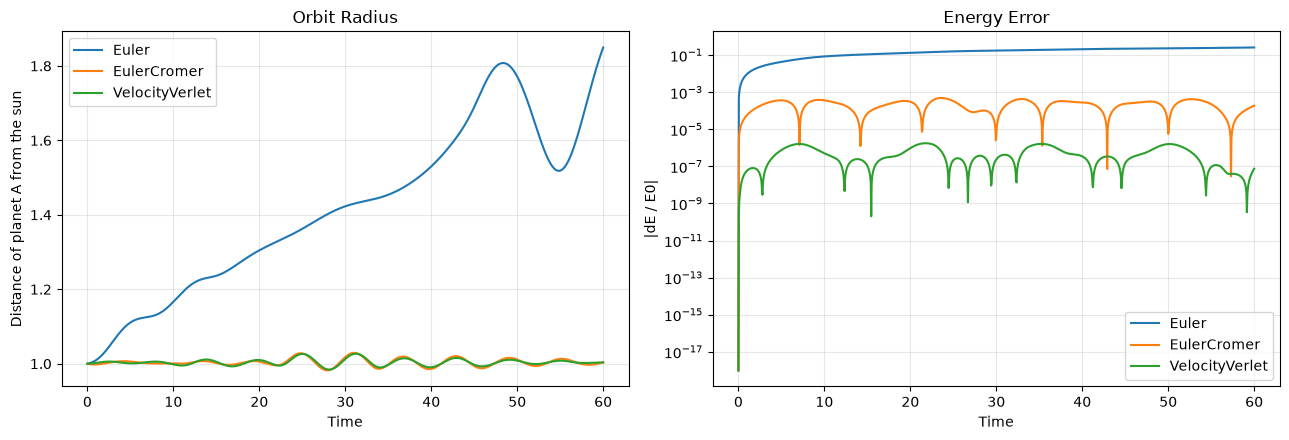

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for name, d in runs.items():
    ax[0].plot(d['t'], d['A.r'], label=name)
    ax[1].semilogy(d['t'], np.abs(d['E'] - d['E'][0]) / abs(d['E'][0]) + 1e-18, label=name)

ax[0].set_xlabel('Time')
ax[0].set_ylabel('Distance of planet A from the sun')
ax[0].set_title('Orbit Radius')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].set_xlabel('Time')
ax[1].set_ylabel('|dE / E0|')
ax[1].set_title('Energy Error')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Euler gains energy and planet A spirals outward. Euler-Cromer stays bounded. Velocity Verlet has an energy error that is a few hundred times smaller than Euler-Cromer's on the same scene. Angular momentum is conserved to rounding error by both symplectic methods, and total momentum is zero to rounding error for all three. Nothing in the world, the forces, or the bodies changed between runs.

## Design Notes

- **Velocity Verlet computes forces twice per step.** The first call gives the old acceleration and the second gives the new one at the updated positions. Caching the acceleration between steps would be faster, but it goes stale when a collider moves a body. Recomputing is slower.
- **Colliders run after the integrator.** A collision does not belong inside the force loop.
- **Broad phase is every pair.** CircleCollisions checks all N(N-1)/2 pairs.
- **Spin is ignored in collisions.** Contacts are frictionless, so a collision changes velocity but never omega. This is the same limitation as in Lab 6's bonus.
- **Ports to JavaScript.** The engine uses numpy, np.dot, and np.linalg.norm. The recorded lists are only turned into arrays at the end of a run.